# Assignment 2 Distribution Grid Simulation

## Notebook C

In [1]:
import pandapower as pp
import pandapower.plotting as plot
import pandas as pd
import numpy as np
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)

GEN_DATA_PATH = "../Data/GenerationData_C.csv"
LOAD_DATA_PATH = "../Data/LoadData_C.csv"


#### Creating the C Dataset Grid Using Pandapower

Convert this code to fit the Grid C

In [2]:
net = pp.create_empty_network()

n = 17  # number of buses, loads and generators

buses = [pp.create_bus(net, vn_kv=20, name="Bus 0")]
# append a list of 10 buses to the list buses
buses.extend([pp.create_bus(net, vn_kv=0.4, name=f"Bus {i}") for i in range(1, n + 1)])

buses.extend([pp.create_bus(net, vn_kv=0.4, name=f"Bus {i}") for i in range(n+1, n + 1 + 10)])

nextline = int(np.ceil(n / 2))
lines1 = [
    pp.create_line(
        net,
        from_bus=buses[i],
        to_bus=buses[i + 1],
        length_km=0.021,
        std_type="NAYY 4x50 SE",
        name=f"Line {i}",
    )
    for i in range(1, int(np.floor(n / 2)))
]

pp.create_line(
    net,
    from_bus=buses[1],
    to_bus=buses[nextline],
    length_km=0.021,
    std_type="NAYY 4x50 SE",
    name=f"connection line",
)

lines2 = [
    pp.create_line(
        net,
        from_bus=buses[i],
        to_bus=buses[i + 1],
        length_km=0.021,
        std_type="NAYY 4x50 SE",
        name=f"Line {i}",
    )
    for i in range(int(np.ceil(n / 2)), n)
]

pp.create_line(
    net,
    from_bus=buses[1],
    to_bus=buses[n+1],
    length_km=0.021,
    std_type="NAYY 4x50 SE",
    name=f"connection line",
)

lines3 = [
    pp.create_line(
        net,
        from_bus=buses[i],
        to_bus=buses[i + 1],
        length_km=0.021,
        std_type="NAYY 4x50 SE",
        name=f"Line {i}",
    )
    for i in range(n + 1, n + 10)
]

pp.create_ext_grid(net, buses[0])
tid = pp.create_transformer(
    net, hv_bus=buses[0], lv_bus=buses[1], std_type="0.4 MVA 20/0.4 kV", name="Trafo"
)

# create loads
loads = [
    pp.create_load(net, buses[i], p_mw=0.0010, q_mvar=0.001, name=f"Load {i}")
    for i in range(1, n + 1 + 10)
]
# create generators
generators = [
    pp.create_sgen(net, buses[i], p_mw=0.0010, q_mvar=0.001, vm_pu=1.0, name=f"Gen {i}")
    for i in range(1, n + 1 + 10)
]


No or insufficient geodata available --> Creating artificial coordinates. This may take some time


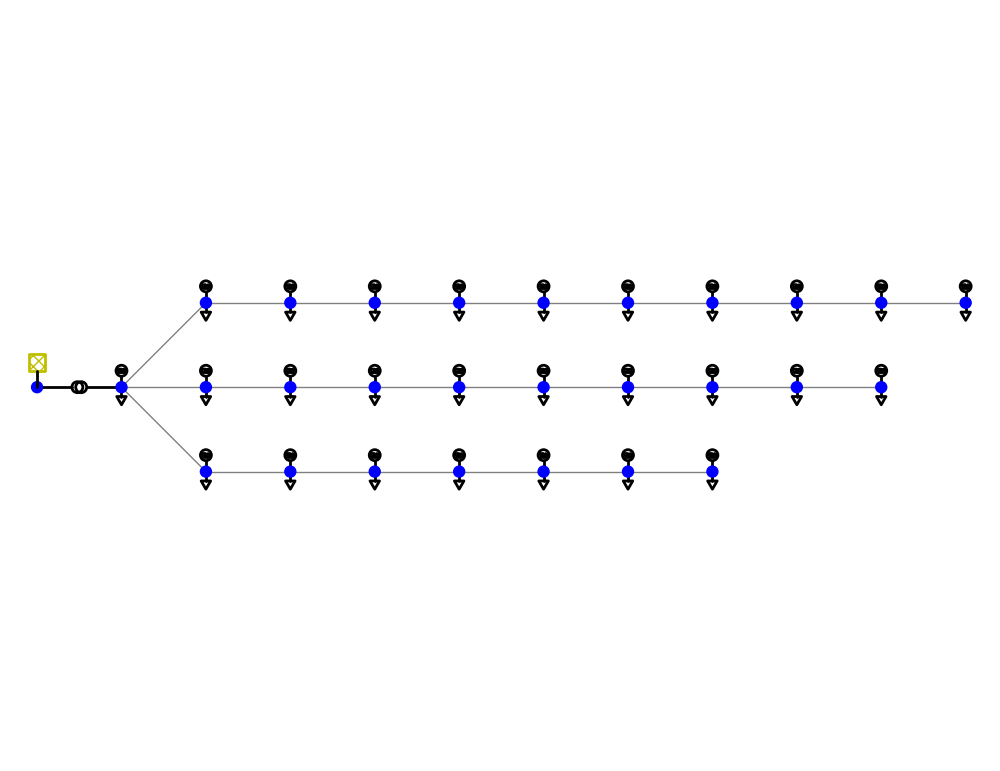

<Axes: >

In [3]:
plot.simple_plot(net, plot_loads=True, plot_sgens=True)

In [4]:
pp.runpp(net)
net.res_ext_grid

NUM_PROFILES = net.load.shape[0]
print(NUM_PROFILES)

27


#### Algorithmic Optimization of Household Allocation

Find and rank the best load-generation pairs based on minimizing peak net load

In [5]:
from rank_best_pairs import rank_best_pairs
ranked_pairs = rank_best_pairs(
    gen_data_path=GEN_DATA_PATH,
    load_data_path=LOAD_DATA_PATH,
    num_profiles=NUM_PROFILES
)
print("Ranked load-generation pairs (best to worst):")
print(ranked_pairs)

Ranked load-generation pairs (best to worst):
[(18, 20), (8, 15), (12, 8), (11, 10), (15, 16), (23, 24), (1, 9), (5, 6), (9, 3), (6, 2), (25, 25), (0, 17), (16, 11), (20, 1), (17, 26), (14, 5), (3, 0), (2, 13), (24, 18), (21, 23), (4, 4), (7, 7), (22, 21), (10, 19), (19, 14), (13, 12), (26, 22)]


Rank a list of buses from "weakest" to "strongest" using the Short Circuit Impedance Method.

In [6]:
from grid_analyzer import rank_buses_by_impedance
residential_bus_indicies = list(range(1, NUM_PROFILES+1))  # buses 1 to 17 (excluding bus 0 which is the external grid)
ranked_buses = rank_buses_by_impedance(net, residential_bus_indicies)

Ranking buses by Short-Circuit Impedance (z_sc)...
Ranked Buses (Weakest to Strongest): [26, 16, 25, 15, 24, 14, 7, 23, 13, 6, 22, 12, 5, 21, 11, 4, 20, 10, 3, 19, 9, 2, 18, 8, 1, 17, 0]


Assign best load generation pairs to weakest bus. Create the "smart" allocation and calculate its sum of max loadings.

In [7]:
from first_guesses import create_smart_seed, create_round_robin_seed
from genetic_algorithm import calculate_fitness
smart_seed_allocation = create_smart_seed(
    ranked_pairs,
    ranked_buses
)

fitness_smart, max_smart = calculate_fitness(
    smart_seed_allocation,
    net,
    gen_data_path=GEN_DATA_PATH,
    load_data_path=LOAD_DATA_PATH
)
print(f"Smart Seed sum of max loadings: ", max_smart)

No time steps to calculate are specified. I'll check the datasource of the first controller for avaiable time steps


Creating smart seed allocation...
Smart seed allocation created.
Load Allocation: [26, 19, 7, 24, 14, 16, 6, 1, 10, 4, 2, 17, 0, 9, 23, 11, 8, 13, 22, 21, 3, 20, 25, 5, 15, 12, 18]
Generation Allocation: [22, 14, 7, 18, 5, 11, 2, 9, 19, 4, 13, 26, 17, 3, 24, 10, 15, 12, 21, 23, 0, 1, 25, 6, 16, 8, 20]


100%|██████████| 24/24 [00:00<00:00, 173.96it/s]

Smart Seed sum of max loadings:  112.67428397190317


Run Round Robin Allocation, to see if is gets a better result than Smart Seed Allocation. 

In [8]:
round_robin_allocation = create_round_robin_seed(
    gen_data_path=GEN_DATA_PATH,
    load_data_path=LOAD_DATA_PATH,
    num_profiles=NUM_PROFILES
)
fitness_rr, max_rr = calculate_fitness(
    round_robin_allocation,
    net,
    gen_data_path=GEN_DATA_PATH,
    load_data_path=LOAD_DATA_PATH
)
print(f"Round Robin sum of max loadings: ", max_rr)

No time steps to calculate are specified. I'll check the datasource of the first controller for avaiable time steps
100%|██████████| 24/24 [00:00<00:00, 159.06it/s]

Round Robin sum of max loadings:  107.8959596400648


Run the genetic algorithm for grid B, using best first guess.

In [20]:
# Decide which initial allocation to use
if max_smart < max_rr:
    print("Using Smart Seed as initial allocation for GA.")
    initial_allocation = smart_seed_allocation
else:
    print("Using Round Robin Seed as initial allocation for GA.")
    initial_allocation = round_robin_allocation

from genetic_algorithm import run_genetic_algorithm
run_genetic_algorithm(
    net,
    gen_data_path=GEN_DATA_PATH,
    load_data_path=LOAD_DATA_PATH,
    initial_allocation=initial_allocation,
    population_size=200,
    num_generations=50,
    tournament_size=10,
    mutation_rate=0.15,
    crossover_rate=0.9
)


No time steps to calculate are specified. I'll check the datasource of the first controller for avaiable time steps


Using Round Robin Seed as initial allocation for GA.
--- Distribution Grid Genetic Algorithm Optimization Test ---
Distribution Grid:
 This pandapower network includes the following parameter tables:
   - bus (28 elements)
   - load (27 elements)
   - sgen (27 elements)
   - ext_grid (1 element)
   - line (26 elements)
   - trafo (1 element)
   - controller (12 elements)
   - output_writer (1 element)
 and the following results tables:
   - res_bus (28 elements)
   - res_line (26 elements)
   - res_trafo (1 element)
   - res_ext_grid (1 element)
   - res_load (27 elements)
   - res_sgen (27 elements)
   - res_bus_sc (27 elements)
   - res_line_sc (26 elements)
   - res_trafo_sc (1 element)
   - res_ext_grid_sc (1 element)
   - res_sgen_sc (27 elements)

Base Allocation Test:
Load Allocation: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26]
Generation Allocation: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 

  0%|          | 0/24 [00:00<?, ?it/s]

100%|██████████| 24/24 [00:00<00:00, 64.30it/s]
No time steps to calculate are specified. I'll check the datasource of the first controller for avaiable time steps


Fitness: 0.007236663708456975, Sum Max Loading: 138.18522461274122

Initial Allocation Test:
Load Allocation: [13, 18, 12, 26, 14, 2, 11, 21, 9, 8, 10, 4, 3, 1, 20, 22, 17, 7, 15, 0, 16, 5, 25, 6, 24, 23, 19]
Generation Allocation: [13, 18, 12, 26, 14, 2, 11, 21, 9, 8, 10, 4, 3, 1, 20, 22, 17, 7, 15, 0, 16, 5, 25, 6, 24, 23, 19]


...

Best Allocation: ([13, 14, 7, 26, 3, 19, 10, 23, 24, 5, 20, 11, 2, 1, 22, 6, 25, 16, 9, 8, 12, 17, 4, 21, 18, 15, 0], [19, 11, 1, 23, 12, 8, 25, 4, 18, 9, 24, 7, 17, 14, 0, 6, 5, 13, 15, 20, 2, 22, 26, 21, 10, 3, 16]), Fitness: 0.010617848230235153, Sum Max Loading: 94.18104104675577

--- Generation 49 / 50 ---
Evaluationg 200 allocations...


No time steps to calculate are specified. I'll check the datasource of the first controller for avaiable time steps
  0%|          | 0/24 [00:00<?, ?it/s]No time steps to calculate are specified. I'll check the datasource of the first controller for avaiable time steps
No time steps to calculate are specified. I'll check the datasource of the first controller for avaiable time steps
  0%|          | 0/24 [00:00<?, ?it/s]No time steps to calculate are specified. I'll check the datasource of the first controller for avaiable time steps
No time steps to calculate are specified. I'll check the datasource of the first controller for avaiable time steps
  0%|          | 0/24 [00:00<?, ?it/s]No time steps to calculate are specified. I'll check the datasource of the first controller for avaiable time steps
No time steps to calculate are specified. I'll check the datasource of the first controller for avaiable time steps
  0%|          | 0/24 [00:00<?, ?it/s]No time steps to calculate are speci

Best Allocation: ([13, 14, 7, 26, 3, 19, 10, 23, 24, 5, 20, 11, 2, 1, 22, 6, 25, 16, 9, 8, 12, 17, 4, 21, 18, 15, 0], [19, 11, 1, 23, 12, 8, 25, 4, 18, 9, 24, 7, 17, 14, 0, 6, 5, 13, 15, 20, 2, 22, 26, 21, 10, 3, 16]), Fitness: 0.010617848230235153, Sum Max Loading: 94.18104104675577

--- Generation 50 / 50 ---
Evaluationg 200 allocations...


No time steps to calculate are specified. I'll check the datasource of the first controller for avaiable time steps
  0%|          | 0/24 [00:00<?, ?it/s]No time steps to calculate are specified. I'll check the datasource of the first controller for avaiable time steps
No time steps to calculate are specified. I'll check the datasource of the first controller for avaiable time steps
  0%|          | 0/24 [00:00<?, ?it/s]No time steps to calculate are specified. I'll check the datasource of the first controller for avaiable time steps
No time steps to calculate are specified. I'll check the datasource of the first controller for avaiable time steps
  0%|          | 0/24 [00:00<?, ?it/s]No time steps to calculate are specified. I'll check the datasource of the first controller for avaiable time steps
No time steps to calculate are specified. I'll check the datasource of the first controller for avaiable time steps
 25%|██▌       | 6/24 [00:00<00:00, 57.26it/s]No time steps to calculate a

Best Allocation: ([13, 14, 7, 26, 3, 19, 10, 23, 24, 5, 20, 11, 2, 1, 22, 6, 25, 16, 9, 8, 12, 17, 4, 21, 18, 15, 0], [19, 11, 1, 23, 12, 8, 25, 4, 18, 9, 24, 7, 17, 14, 0, 6, 5, 13, 15, 20, 2, 22, 26, 21, 10, 3, 16]), Fitness: 0.010617848230235153, Sum Max Loading: 94.18104104675577

=== Genetic Algorithm Optimization Complete ===
Final sum of max loadings: 94.18%
Load Allocation: [13, 14, 7, 26, 3, 19, 10, 23, 24, 5, 20, 11, 2, 1, 22, 6, 25, 16, 9, 8, 12, 17, 4, 21, 18, 15, 0]
Generation Allocation: [19, 11, 1, 23, 12, 8, 25, 4, 18, 9, 24, 7, 17, 14, 0, 6, 5, 13, 15, 20, 2, 22, 26, 21, 10, 3, 16]
Run summary written to: GA runs C/ga_run_C_20251118_121241.json


Plot how the best sum of max loadings evolves over the generations. This can be used for tuning the GA algorithm.

Loading most recent run: GA runs C/ga_run_C_20251118_121241.json


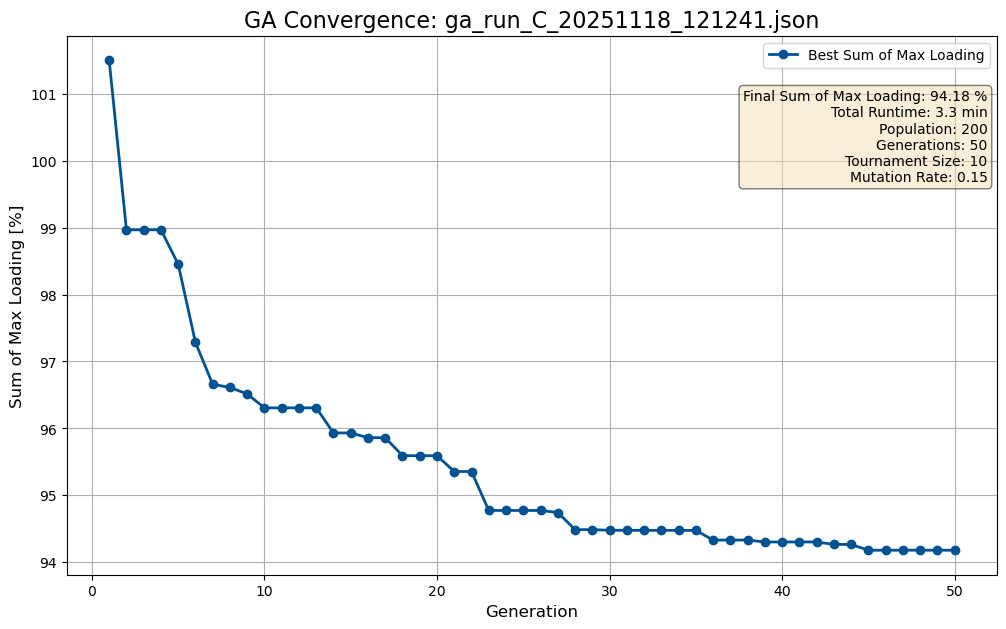

In [21]:
import matplotlib.pyplot as plt
import json 
from pathlib import Path
import glob

run_directory = Path("./GA runs C/")
# Find all JSON files in the directory matching the pattern
search_pattern = str(run_directory / "ga_run_C_*.json")
all_run_files = glob.glob(search_pattern)

if not all_run_files:
    print("No GA run files found.")
else:
    # Find the most recent file
    try:
        latest_file = max(all_run_files)
        print(f"Loading most recent run: {latest_file}")
    except Exception as e:
        print(f"Error finding the most recent file: {e}")
    
    try: 
        # Load and parse that data
        with open(latest_file, 'r') as f:
            data = json.load(f)

        # The 'generation_logs' key contains the list of data points
        logs = data.get('generation_logs')

        if not logs:
            print("Error: JSON file does not contain 'generation_logs' key or it is empty.")
        else:
            # Convert to a DataFrame for easier plotting
            df = pd.DataFrame(logs)
            
            # Calculate the *true* convergence
            # 'best_loading' is the best for that generation
            df['overall_best_loading'] = df['best_loading'].cummin()

            # Create the plot
            fig, ax = plt.subplots(figsize=(12, 7))
            
            # Plot the overall best (solid line)
            ax.plot(df['generation'], df['overall_best_loading'], 
                         linestyle='-', 
                         marker='o', 
                         color='#005293', 
                         linewidth=2, 
                         label='Best Sum of Max Loading')
            
            # Add title and labels
            ax.set_title(f"GA Convergence: {Path(latest_file).name}", fontsize=16)
            ax.set_xlabel("Generation", fontsize=12)
            ax.set_ylabel("Sum of Max Loading [%]", fontsize=12)
            ax.legend(fontsize=10)
            ax.grid(True)
                
            # Add a text box with final results from the top-level keys
            final_best = data.get('overall_best_loading', 0)
            run_time = data.get('runtime_seconds', 0)
            pop_size = data.get('pop_size', 'N/A')
            num_gen = data.get('num_generations', 'N/A')
            tournament_size = data.get('tournament_size', 'N/A')
            mutation_rate = data.get('mutation_rate', 'N/A')
                
            text_str = (
                f"Final Sum of Max Loading: {final_best:.2f} %\n"
                f"Total Runtime: {run_time / 60:.1f} min\n"
                f"Population: {pop_size}\n"
                f"Generations: {num_gen}\n"
                f"Tournament Size: {tournament_size}\n"
                f"Mutation Rate: {mutation_rate}"
            )

            # Place a text box in upper right in axes coords
            props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
            ax.text(0.99, 0.90, text_str, 
                     transform=ax.transAxes, 
                     fontsize=10,
                     verticalalignment='top', 
                     horizontalalignment='right', 
                     bbox=props)
            
            # Save the plot 
            plt.savefig('../Figures/GA_Convergence_latest_run.png', dpi=300)
            # 8. Show the plot in a new window
            plt.show()

    except json.JSONDecodeError as e:
        print(f"Error decoding JSON from file {latest_file}: {e}")
    except Exception as e:
        print(f"Error loading or processing file {latest_file}: {e}")
